In [47]:
import sys

sys.path.append("../src")
from data_validation import validate_dataframe
import glob
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pandas.errors import EmptyDataError
import seaborn as sns
from typing import Literal

In [48]:
first_20_path = r"C:\Users\Aamir Bin Abbas\Desktop\Research & Thesis\Quantitative Stock Market Analysis\data\processed\yahoo_finance\first_20_companies"

In [49]:
def get_dataset(filepath: str, file_num: int) -> pd.DataFrame:
    """Helper function to accessing csv files in directory

    Args:
        filepath (str): directory path to containing csv files
        file_num (int): list index number of the file list

    Returns:
        pd.DataFrame: pandas dataframe
    """
    dataset_dir = glob.glob(f"{filepath}/*.csv")

    df = pd.read_csv(dataset_dir[file_num])

    return df

In [50]:
master_df = get_dataset(first_20_path,0)

In [51]:
def check_monotonic(
    dataset: pd.DataFrame
    ) -> bool:
    """Check if dates are monotonic or not

    Args:
        dataset (pd.DataFrame): current pandas dataset(note: date column must be datetime format)

    Raises:
        EmptyDataError: raised when dataset is empty

    Returns:
        bool: True if monotonic else False
    """

    validate_dataframe(dataset)

    date_col = [col for col in dataset.columns]

    for column in date_col:
        if pd.api.types.is_datetime64_any_dtype(dataset[column]):
            is_increasing = dataset[column].is_monotonic_increasing

            is_decreasing = dataset[column].is_monotonic_decreasing

            return is_increasing or is_decreasing

    return False

In [52]:
def column_check(dataset: pd.DataFrame) -> bool:
    """Checks required columns availability

    Args:
        dataset (pd.DataFrame): A pandas dataframe

    Returns:
        bool: returns True for "OHLCV" including "Date" & 'Ticker' is available else False
    """
    
    validate_dataframe(dataset)
    
    req_col = ['Close', 'High', 'Low', 'Open', 'Volume', 'Ticker', 'Date']
    
    clean_req = []
    
    for col in req_col:
        clean_req.append(col.strip().lower()) 
        
    actual_col = [col for col in dataset.columns]

    clean_actual = []
    
    for col in actual_col:
        clean_actual.append(col.strip().lower()) 
        
        
    required = set(clean_req)
    actual = set(clean_actual)
    
    if required.issubset(actual):
        return True

    return False

In [53]:
def convert_date(
    dataset: pd.DataFrame, date_col: str, errors: Literal["raise", "coerce"] = "coerce"
) -> pd.DataFrame:
    """Convert 'Date' column in the dataset.
        Warning :  Using errors='coerce' converts invalid date values to NaT.

    Args:
        dataset (pd.DataFrame): The input pandas DataFrame.
        date_col (str): Name of the column to convert. Case-sensitive.
        errors (Literal['raise', 'coerce']): Determines how invalid date values
        are handled. Defaults to 'coerce'.
        - 'raise': Raises an exception when an invalid date is encountered.
        - 'coerce': Converts invalid date values to NaT.

    Raises:
        EmptyDataError: raises error if dataset is empty
        KeyError: raises error if the date column is not present in the dataset

    Returns:
        pd.DataFrame: The DataFrame with the specified column converted to pandas datetime.
    """
    validate_dataframe(dataset)

    if date_col not in dataset.columns:
        raise KeyError(f"No {date_col} was found in the dataset")

    dataset[date_col] = pd.to_datetime(dataset[date_col], errors=errors)

    return dataset

In [54]:
def round_float(dataset: pd.DataFrame, r: int = 2) -> pd.DataFrame:
    """
    Round floating-point columns in a Pandas DataFrame.

    Rounds all floating-point columns to the specified decimal
    precision. The default precision is 2 decimal places.

    Args:
        dataset (pd.DataFrame): The DataFrame to be modified.
        r (int): Number of decimal places to retain. Defaults to 2.

    Raises:
        TypeError: If dataset is not a DataFrame or r is not an integer.
        ValueError: If r is negative.
        EmptyDataError: If the provided DataFrame is empty.

    Returns:
        pd.DataFrame: The modified DataFrame with rounded float columns.
    """
    validate_dataframe(dataset)

    if isinstance(r, bool) or isinstance(r, float):
        raise TypeError(
            f"The arg {r} provided must be an integer, got {type(r).__name__}"
        )

    if r < 0:
        raise ValueError("The rounding parameter 'r' must be 0 or greater.")

    columns = [col for col in dataset.columns]

    for col in columns:
        if pd.api.types.is_float_dtype(dataset[col]):
            dataset[col] = round(dataset[col], r)

    return dataset

# Short-Term Trends

**Time Horizon:** Intraday (minutes/hours) to several weeks or months.

**Key Indicators:**
- MA20 (20-period moving average)
- Daily returns
- Volatility
- Trading volume spikes
- News sentiment

**Financial Significance:** Helps identify recent momentum and potential trading opportunities.

In [55]:
def duplicate_date_check(dataset: pd.DataFrame):
    """Check and raises error if duplicate dates are found

    Args:
        dataset (pd.DataFrame): a pandas dataframe

    Raises:
        ValueError: raises if duplicate dates are found
    """
    for col in dataset.columns:
        if pd.api.types.is_datetime64_any_dtype(dataset[col]):
            if dataset[col].duplicated().sum() > 0:
                raise ValueError(f"Duplicate dates found in column: {col}")

In [56]:
def calculate_moving_average(
    dataset: pd.DataFrame,
    ) -> pd.DataFrame:
    """Calculates Moving Averages from Short to Long Term Trends (MA20,MA50,MA200) and appends to existing dataframe

    Args:
        dataset (pd.DataFrame): a pandas dataframe

    Raises:
        ValueError: raises if dataset if not monotonically increasing
        validate_dataframe (function): raises errors if dataset is empty or not a pandas dataframe

    Returns:
        pd.DataFrame: a pandas dataframe
    """
    
    validate_dataframe(dataset)
    
    convert_date(dataset,'Date') # default error = 'coerce'
    
    # important checks before rolling average
    if not check_monotonic(dataset):
        raise ValueError('The dataframe must be monotonically increasing')
    
    # duplicate check 
    duplicate_date_check(dataset)
    
    dataset['MA20'] = dataset['Close'].rolling(window=20).mean()    
    dataset['MA50'] = dataset['Close'].rolling(window=50).mean()    
    dataset['MA200'] = dataset['Close'].rolling(window=200).mean()    
    
    return dataset

Short term analysis (MA20) helps identify recent momentum potential opportunity whereas long term analysis (MA200) is widely used and respected trend indicator.

A new data frame containing the selected features was createdpost calculation using “Featured used” columns. TheClose price, MA20, MA50, and MA200were plotted on a single line chart usingDate as the x-axis. Plotting all series on the same graph enables direct comparison of price movements and moving-average relationships, making bullish periods, bearish periods, and crossover signals easier to identify.



In [57]:
df = get_dataset(first_20_path,0)


In [58]:
pipe = (convert_date(df,'Date'),
check_monotonic(df),
column_check(df),
calculate_moving_average(df),
round_float(df)
)

In [ ]:
#For automatic plotting in Jupyter, can be removed as required
%matplotlib widget 

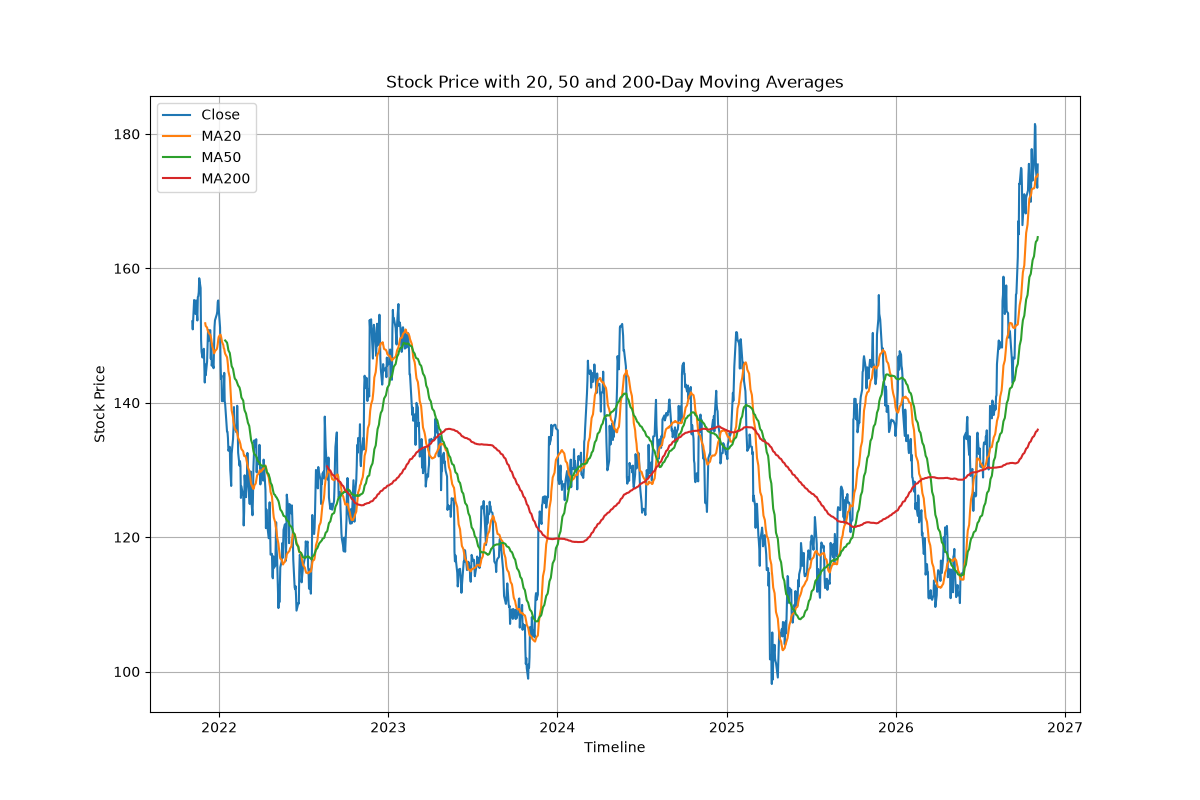

In [60]:
plt.figure(figsize=(12, 8))
plt.plot(df['Date'],df['Close'],label = 'Close')
plt.plot(df['Date'],df['MA20'],label = 'MA20')
plt.plot(df['Date'],df['MA50'],label = 'MA50')
plt.plot(df['Date'],df['MA200'],label = 'MA200')
plt.grid(True)
plt.xlabel('Timeline')
plt.ylabel('Stock Price')
plt.title("Stock Price with 20, 50 and 200-Day Moving Averages")
plt.legend()
plt.show()


# Definitions and interpretations

*Bearish Period*: Price < MA20 < MA50 < MA20
-   *coordinates (approx)* = (2026,181.5)
-  *Financial Interpretation*:  This structure suggests persistent weak and negative sentiment.

*Bullish Period*: Price > MA20 > MA50 > MA200 
- *coordinates (approx)*= (2023,99)
- *Financial Interpretation*: Investors generally interpret this alignment as strong upward momentum and positive market sentiment

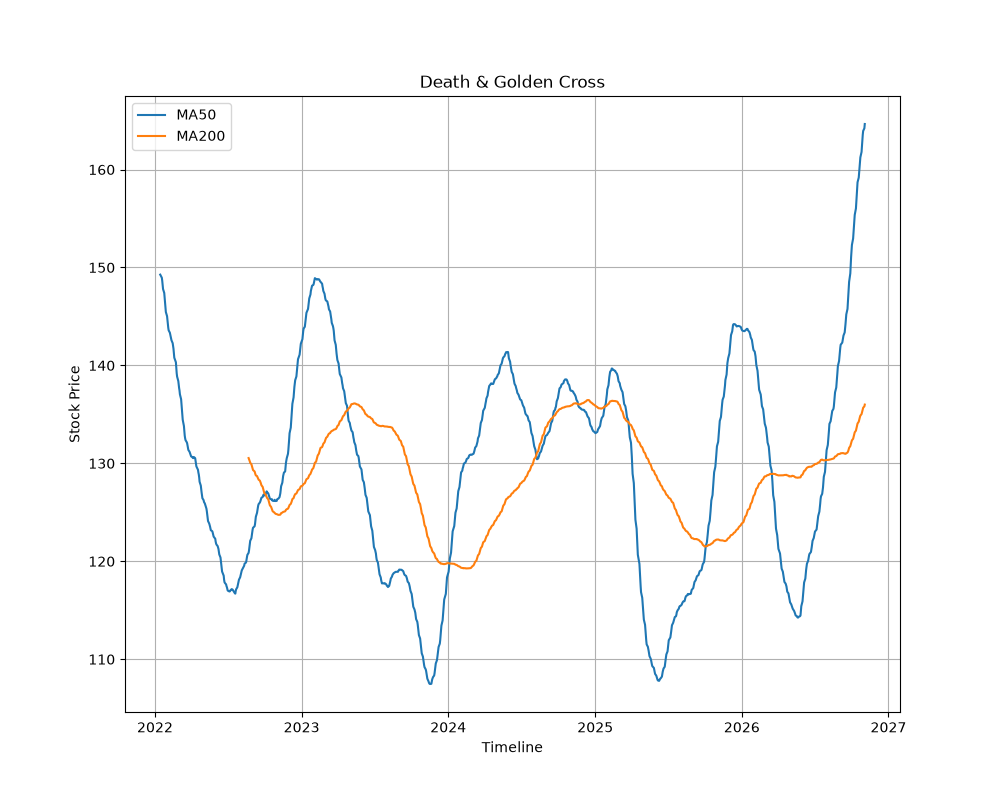

In [61]:
plt.figure(figsize=(10,8))
plt.plot(df['Date'],df['MA50'],label = "MA50")
plt.plot(df['Date'],df['MA200'],label = "MA200")
plt.grid(True)
plt.xlabel("Timeline")
plt.ylabel("Stock Price")
plt.title("Death & Golden Cross")
plt.legend()
plt.show()


# Definitions and interpretations

*Golden Cross*: This occurs when MA50 and MA200 intersect (MA50 crosses above MA200).
- *Financial Interpretation*:The medium-term trend has become stronger than the long-term trend, often signaling the beginning of a bullish market.

*Death Cross*: This occurs when MA50 crosses below the MA200.
- *Financial Interpretation*: The medium-term trend has weakened relative to the long-term trend, often signaling a bearish market phase..

**Note**: ***Golden Cross(Bullish)*** always occurs when MA50 is above MA200 and ***Death Cross (Bearish)*** always occurs when MA50 is below MA200

To check relationship between Open,High,Low,Close and Volume , a correlation matrix measures the strength and direction of the linear relationship between variables.

*Financial Interpretation*: Highly correlated price variables often contain similar information, whereas volume may provide additional insight into market participation and liquidity.

In [62]:
def correlation_matrix(
    dataset: pd.DataFrame
    ) -> pd.DataFrame:
    
    # checks and raises errors (refer above functions) 
    validate_dataframe(dataset) 
    duplicate_date_check(dataset)
    column_check(dataset)
    
    corr = dataset[['Open', 'High', 'Low', 'Close', 'Volume']].corr()
    
    return corr

In [63]:
correlation_matrix(df)

,Open,High,Low,Close,Volume
Open,1.000000,0.995242,0.995543,0.989763,-0.128744
High,0.995242,1.000000,0.994852,0.995790,-0.102492
Low,0.995543,0.994852,1.000000,0.995350,-0.148209
Close,0.989763,0.995790,0.995350,1.000000,-0.122742
Volume,-0.128744,-0.102492,-0.148209,-0.122742,1.000000


A *heatmap* is used to visually represent the correlation matrix. Different colors indicate the strength and direction of correlations between Open, High, Low, Close, and Volume

*Purpose*: The heatmap enables rapid identification of strongly and weakly correlated variable pairs and helps detect potential multi-collinearity among price-related features.

In [64]:
corr = correlation_matrix(df)
round_float(corr,r =5) # kept 5 decimal points

,Open,High,Low,Close,Volume
Open,1.00000,0.99524,0.99554,0.98976,-0.12874
High,0.99524,1.00000,0.99485,0.99579,-0.10249
Low,0.99554,0.99485,1.00000,0.99535,-0.14821
Close,0.98976,0.99579,0.99535,1.00000,-0.12274
Volume,-0.12874,-0.10249,-0.14821,-0.12274,1.00000


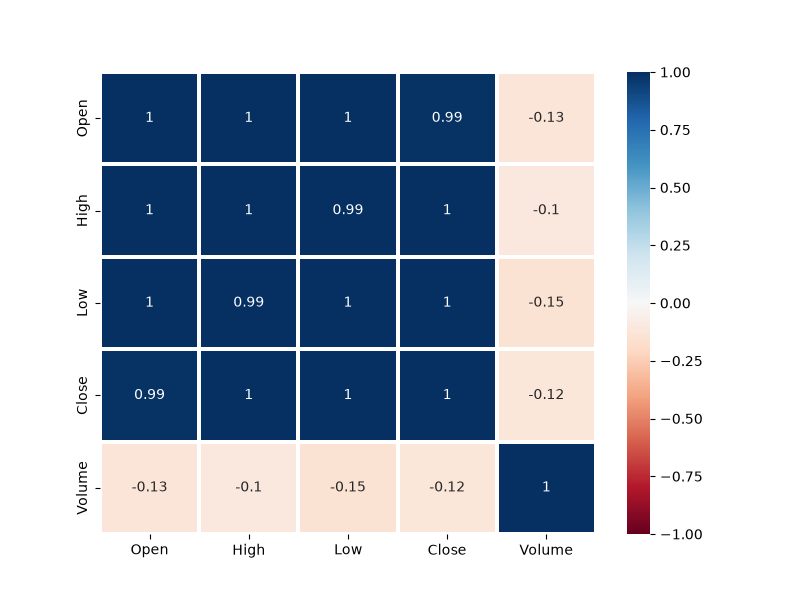

In [65]:
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap='RdBu', vmin=-1, vmax=1, center=0,linewidths= 1.5)
plt.show()

*Interpretation*:
 - +1: perfect positive relationship
-   0: no linear relationship
-  -1: perfect negative relationship

*Financial Interpretation*: Highly correlated price variables often contain similar information, whereas volume may provide additional insight into market participation and liquidity.

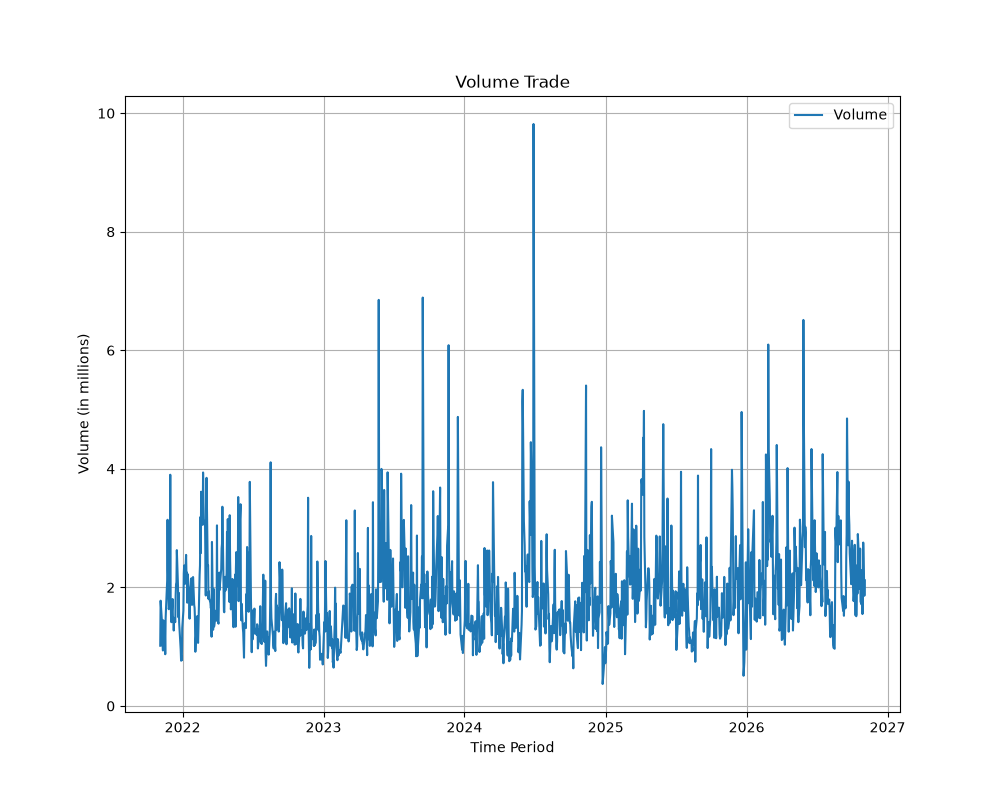

In [74]:
scaled_volume = df['Volume'] / 1_000_000

plt.figure(figsize=(10,8))
plt.plot(df['Date'],scaled_volume,label='Volume')
plt.title('Volume Trade')
plt.ylabel('Volume (in millions)')
plt.xlabel('Time Period')
plt.grid(True)
plt.legend()
plt.show()

The trading volume values were scaled down to millions to improve readability and make visualization easier.

This transformation does not result in information loss because it is reversible:

*Original Volume= Displayed Volume \ 1,000,000*

The original dataset remains unchanged; scaling is applied only during visualization.

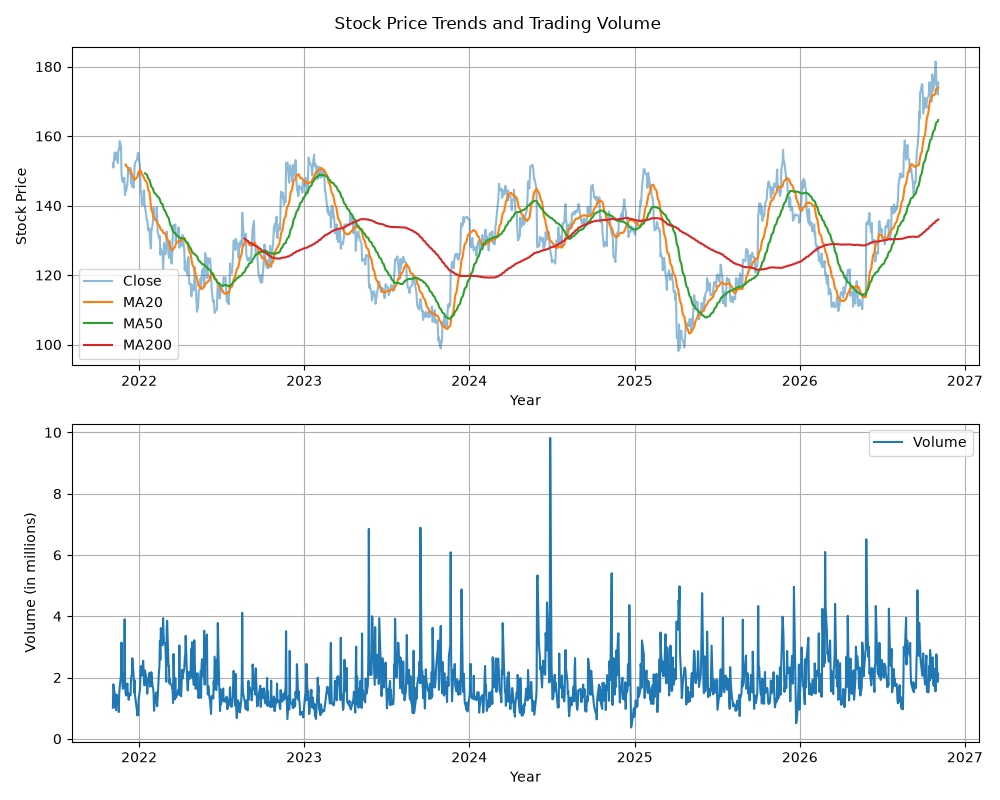

In [99]:
plt.figure(figsize=(10,8))

# 1st figure
plt.subplot(2,1,1)
plt.plot(df['Date'],df['Close'],label='Close',alpha = 0.5)
plt.plot(df['Date'],df['MA20'],label='MA20')
plt.plot(df['Date'],df['MA50'],label='MA50')
plt.plot(df['Date'],df['MA200'],label='MA200')
plt.xlabel('Year')
plt.ylabel('Stock Price')
plt.grid(True)
plt.legend()



# 2nd figure
plt.subplot(2,1,2)
plt.plot(df['Date'],scaled_volume,label='Volume')
plt.grid(True)
plt.xlabel('Year')
plt.ylabel('Volume (in millions)')
plt.legend()



plt.suptitle('Stock Price Trends and Trading Volume ')
plt.tight_layout()
plt.show()

Trading volume experienced significant spikes during mid-2024, coinciding with periods of relatively low stock prices.Several other can also be observed during other peak trading whenever the price dipped post-mid 2024.

This indicates increased trading activity during periods of price weakness. Such behavior may reflect heightened market interest, selling pressure, or potential accumulation.

However, volume alone cannot establish the direction of investor positioning or determine which investor groups benefited from these movements.